In [1]:
import pandas as pd
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import h5py
from scipy.interpolate import LinearNDInterpolator, Rbf
from matplotlib.colors import Normalize
import matplotlib as mpl
import cmasher as cmr
from astropy.io import fits
from astropy.table import Table

In [5]:
r = float(np.float64(1.23))
type(r)


float

## NLTE Corrections for Na I, Mg I and Al I
### From Lind et al. (2022)

This his done via the Julia code **nlte_corr.jl**. Look there for how we perform the NLTE corrections using these grids

## NLTE Corrections for Sr II, Ba II and Eu II

### Inputs

These will be done using the spectrum.inasan.ru web interface (https://spectrum.inasan.ru/nLTE2/). The interface requires the following:
- Teff
- Logg
- [Fe/H]
- [X/Fe]

The web interface only accepts one line per element for a set of stars, so will need to make a file for each line containing the above parameters

In [37]:
# Loading in the Sr II data
all_sr_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sr_II_allabunds_line.csv")
inasan_sr4077_entry = all_sr_abunds[all_sr_abunds['line'] == 'Sr_4077.709'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]
inasan_sr4077_entry_detect = inasan_sr4077_entry[inasan_sr4077_entry['detection'] == 'Y']
inasan_sr4077_entry_nondetect = inasan_sr4077_entry[inasan_sr4077_entry['detection'] == 'N']
inasan_sr4077_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/sr4077_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_sr4077_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/sr4077_detect_starids.txt", sep=" ", index=False, header=False, float_format="%.2f")
if len(inasan_sr4077_entry_nondetect) > 0:
    inasan_sr4077_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/sr4077_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_sr4077_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/sr4077_nondetect_starids.txt", sep=" ", index=False, header=False, float_format="%.2f")


# Loading in the Ba II data
all_ba_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ba_II_allabunds_line.csv")
inasan_ba4554_entry = all_ba_abunds[all_ba_abunds['line'] == 'Ba_4554.032'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]

inasan_ba4554_entry_detect = inasan_ba4554_entry[inasan_ba4554_entry['detection'] == 'Y']
inasan_ba4554_entry_nondetect = inasan_ba4554_entry[inasan_ba4554_entry['detection'] == 'N']
inasan_ba4554_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4554_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_ba4554_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4554_detect_starids.txt", sep=" ", index=False, header=False)
if len(inasan_ba4554_entry_nondetect) > 0:
    inasan_ba4554_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4554_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_ba4554_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4554_nondetect_starids.txt", sep=" ", index=False, header=False)

inasan_ba4934_entry = all_ba_abunds[all_ba_abunds['line'] == 'Ba_4934.077'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]
inasan_ba4934_entry_detect = inasan_ba4934_entry[inasan_ba4934_entry['detection'] == 'Y']
inasan_ba4934_entry_nondetect = inasan_ba4934_entry[inasan_ba4934_entry['detection'] == 'N']
inasan_ba4934_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4934_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_ba4934_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4934_detect_starids.txt", sep=" ", index=False, header=False, float_format="%.2f")
if len(inasan_ba4934_entry_nondetect) > 0:
    inasan_ba4934_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4934_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_ba4934_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba4934_nondetect_starids.txt", sep=" ", index=False, header=False)
    
inasan_ba6496_entry = all_ba_abunds[all_ba_abunds['line'] == 'Ba_6496.897'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]
inasan_ba6496_entry_detect = inasan_ba6496_entry[inasan_ba6496_entry['detection'] == 'Y']
inasan_ba6496_entry_nondetect = inasan_ba6496_entry[inasan_ba6496_entry['detection'] == 'N']
inasan_ba6496_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba6496_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_ba6496_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba6496_detect_starids.txt", sep=" ", index=False, header=False)
if len(inasan_ba6496_entry_nondetect) > 0:
    inasan_ba6496_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba6496_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_ba6496_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/ba6496_nondetect_starids.txt", sep=" ", index=False, header=False)


# Loading in the Eu II data
all_eu_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Eu_II_allabunds_line.csv")
inasan_eu4129_entry = all_eu_abunds[all_eu_abunds['line'] == 'Eu_4129.725'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]
inasan_eu4129_entry_detect = inasan_eu4129_entry[inasan_eu4129_entry['detection'] == 'Y']
inasan_eu4129_entry_nondetect = inasan_eu4129_entry[inasan_eu4129_entry['detection'] == 'N']
inasan_eu4129_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4129_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_eu4129_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4129_detect_starids.txt", sep=" ", index=False, header=False)
if len(inasan_eu4129_entry_nondetect) > 0:
    inasan_eu4129_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4129_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_eu4129_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4129_nondetect_starids.txt", sep=" ", index=False, header=False)
    
inasan_eu4205_entry = all_eu_abunds[all_eu_abunds['line'] == 'Eu_4205.042'][['star_id', 'teff', 'logg', 'feh', 'abund_xfe', 'detection', 'ul']]
inasan_eu4205_entry_detect = inasan_eu4205_entry[inasan_eu4205_entry['detection'] == 'Y']
inasan_eu4205_entry_nondetect = inasan_eu4205_entry[inasan_eu4205_entry['detection'] == 'N']
inasan_eu4205_entry_detect[['teff', 'logg', 'feh', 'abund_xfe']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4205_detect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
inasan_eu4205_entry_detect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4205_detect_starids.txt", sep=" ", index=False, header=False)
if len(inasan_eu4205_entry_nondetect) > 0:
    inasan_eu4205_entry_nondetect[['teff', 'logg', 'feh', 'ul']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4205_nondetect_inputs.txt", sep=" ", index=False, header=False, float_format="%.2f")
    inasan_eu4205_entry_nondetect[['star_id']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_inputs/eu4205_nondetect_starids.txt", sep=" ", index=False, header=False)

### Outputs

In [4]:
ba4554_detect_corrs = np.genfromtxt("/data/misfit/benlowe/xshooter/nlte_corrs/inasan_outputs/ba4554_detect_corrs.dat")

ValueError: Some errors were detected !
    Line #3 (got 8 columns instead of 6)
    Line #5 (got 8 columns instead of 6)
    Line #6 (got 8 columns instead of 6)
    Line #10 (got 8 columns instead of 6)
    Line #12 (got 8 columns instead of 6)
    Line #19 (got 8 columns instead of 6)

## NLTE Corrections for Ti II, Mn I, Co I, Si I and Cr I

These will be done using the MPIA web interface (https://nlte.mpia.de/gui-siuAC_secE.php). The interface requires the following:
- star ID
- Teff
- logg
- [Fe/H]
- Vmic

Each star is on one line, and each value is separated by a space. Since it does not require the [X/Fe] abundance, we can simply extrapolate this for the different lines used for the given element.

In [36]:
# Loading in the Ti II data
all_ti_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ti_II_allabunds.csv")
mpia_ti_entry = all_ti_abunds[['star_id', 'teff', 'logg', 'feh', 'vmic', 'detection', 'upper_limit_xfe']]
mpia_ti_entry_detect = mpia_ti_entry[mpia_ti_entry['detection'] == 'Y']
mpia_ti_entry_nondetect = mpia_ti_entry[mpia_ti_entry['detection'] == 'N']
mpia_ti_entry_detect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/ti_detect_inputs.txt", sep=" ", index=False, header=False)
if len(mpia_ti_entry_nondetect) > 0:
    mpia_ti_entry_nondetect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/ti_nondetect_inputs.txt", sep=" ", index=False, header=False)

# Loading in the Mn I data
all_mn_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mn_I_allabunds.csv")
mpia_mn_entry = all_mn_abunds[['star_id', 'teff', 'logg', 'feh', 'vmic', 'detection', 'upper_limit_xfe']]
mpia_mn_entry_detect = mpia_mn_entry[mpia_mn_entry['detection'] == 'Y']
mpia_mn_entry_nondetect = mpia_mn_entry[mpia_mn_entry['detection'] == 'N']
mpia_mn_entry_detect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/mn_detect_inputs.txt", sep=" ", index=False, header=False)
if len(mpia_mn_entry_nondetect) > 0:
    mpia_mn_entry_nondetect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/mn_nondetect_inputs.txt", sep=" ", index=False, header=False)

# Loading in the Co I data
all_co_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Co_I_allabunds.csv")
mpia_co_entry = all_co_abunds[['star_id', 'teff', 'logg', 'feh', 'vmic', 'detection', 'upper_limit_xfe']]
mpia_co_entry_detect = mpia_co_entry[mpia_co_entry['detection'] == 'Y']
mpia_co_entry_nondetect = mpia_co_entry[mpia_co_entry['detection'] == 'N']
mpia_co_entry_detect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/co_detect_inputs.txt", sep=" ", index=False, header=False)
if len(mpia_co_entry_nondetect) > 0:
    mpia_co_entry_nondetect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/co_nondetect_inputs.txt", sep=" ", index=False, header=False)

# Loading in the Si I data
all_si_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Si_I_allabunds.csv")
mpia_si_entry = all_si_abunds[['star_id', 'teff', 'logg', 'feh', 'vmic', 'detection', 'upper_limit_xfe']]
mpia_si_entry_detect = mpia_si_entry[mpia_si_entry['detection'] == 'Y']
mpia_si_entry_nondetect = mpia_si_entry[mpia_si_entry['detection'] == 'N']
mpia_si_entry_detect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/si_detect_inputs.txt", sep=" ", index=False, header=False)
if len(mpia_si_entry_nondetect) > 0:
    mpia_si_entry_nondetect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/si_nondetect_inputs.txt", sep=" ", index=False, header=False)

# Loading in the Cr data
all_cr_abunds = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Cr_I_allabunds.csv")
mpia_cr_entry = all_cr_abunds[['star_id', 'teff', 'logg', 'feh', 'vmic', 'detection', 'upper_limit_xfe']]
mpia_cr_entry_detect = mpia_cr_entry[mpia_cr_entry['detection'] == 'Y']
mpia_cr_entry_nondetect = mpia_cr_entry[mpia_cr_entry['detection'] == 'N']
mpia_cr_entry_detect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/cr_detect_inputs.txt", sep=" ", index=False, header=False)
if len(mpia_cr_entry_nondetect) > 0:
    mpia_cr_entry_nondetect[['star_id', 'teff', 'logg', 'feh', 'vmic']].to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/cr_nondetect_inputs.txt", sep=" ", index=False, header=False)
# mpia_cr_entry.to_csv("/data/misfit/benlowe/xshooter/nlte_corrs/mpia_inputs/cr_inputs.txt", sep=" ", index=False, header=False)

## NLTE Corrections for Ca-II 
### From Osorio et al. (2022)

Getting the range of all Ca-II corrections for both P113 and P115 stars

In [19]:
# NLTE corrections for P113 stars
p113_path = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
p113_stars = [s for s in os.listdir(p113_path) if s[-3:] != 'csv']

p113_ca_corrs = []
for star in p113_stars:
    p113_star_path = f"{p113_path}{star}/Ca_II/iter_1/Ca_results.csv"
    p113_star_ca = pd.read_csv(p113_star_path)
    p113_star_ca_nltecorr = p113_star_ca['nlte_corr'].mean()
    
    p113_star_dict = {'star_id': star, 'ca_nlte_corr': p113_star_ca_nltecorr}
    p113_ca_corrs.append(p113_star_dict)
p113_ca_corrs_df = pd.DataFrame(p113_ca_corrs)

# NLTE corrections for P115 stars
p115_path = '/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/'
p115_stars = [s for s in os.listdir(p115_path) if s[-3:] != 'csv']

p115_ca_corrs = []
for star in p115_stars:
    p115_star_path = f"{p115_path}{star}/Ca_II/iter_1/Ca_results.csv"
    p115_star_ca = pd.read_csv(p115_star_path)
    p115_star_ca_nltecorr = p115_star_ca['nlte_corr'].mean()
    
    p115_star_dict = {'star_id': star, 'ca_nlte_corr': p115_star_ca_nltecorr}
    p115_ca_corrs.append(p115_star_dict)
p115_ca_corrs_df = pd.DataFrame(p115_ca_corrs)

# Merging the dataframes together
comb_ca_corrs_df = pd.concat([p113_ca_corrs_df, p115_ca_corrs_df], ignore_index=True)

print(f"Min corr: {comb_ca_corrs_df['ca_nlte_corr'].min():.2f}")
print(f"Max corr: {comb_ca_corrs_df['ca_nlte_corr'].max():.2f}")

Min corr: -0.39
Max corr: -0.17


In [11]:
s = 'Al_I_abunds.csv'
s[-4:]

'.csv'

Loading in the data

     Teff  log_g  Fe_H  CaII_8498  CaII_8542  CaII_8662
0    4500    1.0  -2.5     -0.171     -0.224     -0.175
8    4500    2.0  -2.5     -0.195     -0.290     -0.222
16   4500    3.0  -2.5     -0.208     -0.423     -0.293
24   4500    4.0  -2.5     -0.232     -0.546     -0.371
26   5000    1.0  -2.5     -0.272     -0.248     -0.244
34   5000    2.0  -2.5     -0.310     -0.294     -0.294
42   5000    3.0  -2.5     -0.283     -0.344     -0.304
50   5000    4.0  -2.5     -0.240     -0.422     -0.314
58   5500    1.0  -2.5     -0.302     -0.244     -0.268
66   5500    2.0  -2.5     -0.363     -0.302     -0.341
74   5500    3.0  -2.5     -0.350     -0.318     -0.345
82   5500    4.0  -2.5     -0.279     -0.306     -0.296
90   6000    2.0  -2.5     -0.386     -0.340     -0.395
98   6000    3.0  -2.5     -0.398     -0.364     -0.417
106  6000    4.0  -2.5     -0.321     -0.312     -0.335
114  6500    3.0  -2.5     -0.407     -0.430     -0.494
122  6500    4.0  -2.5     -0.333     -0.362    

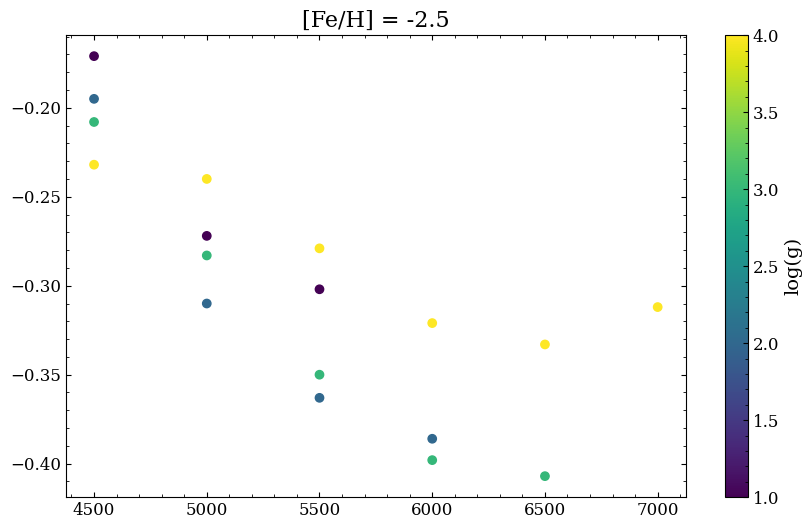

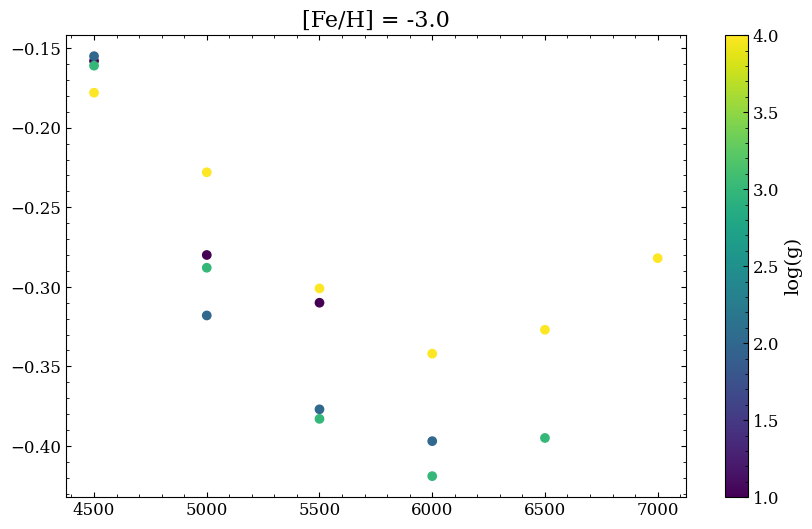

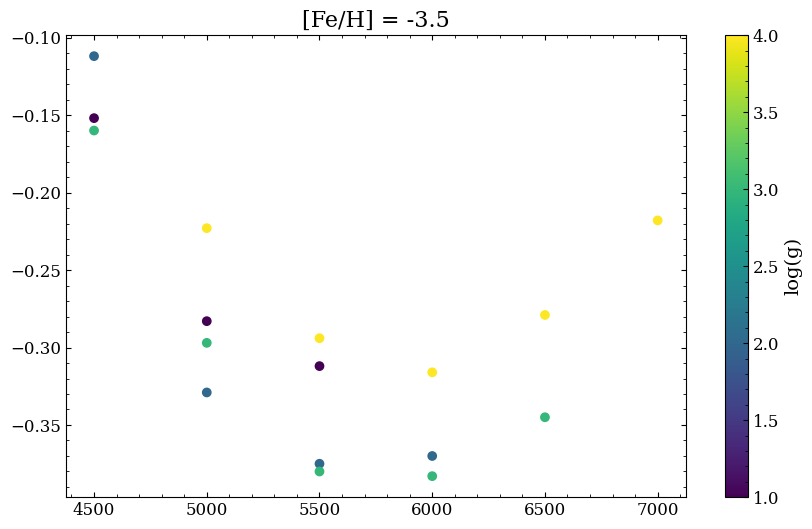

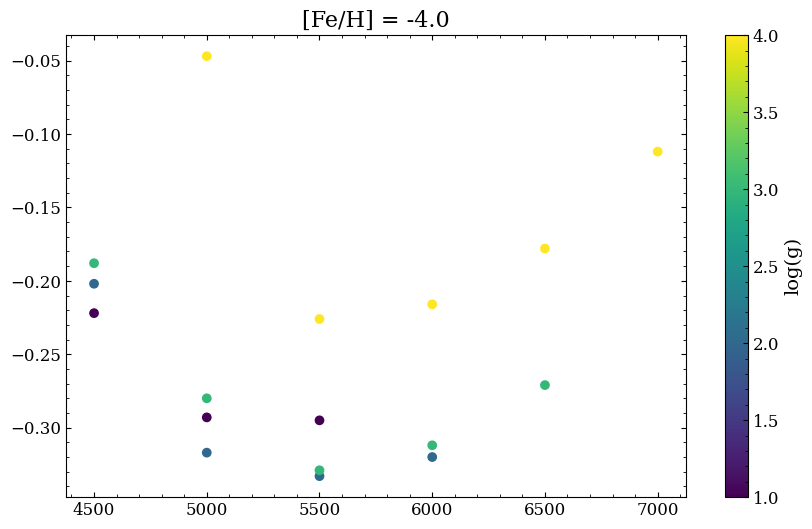

In [2]:
# Loading in the data
caII_corrs = pd.read_csv('/data/misfit/benlowe/xshooter/CaII_nlte_corrections/osorio_corrs.csv')

# Separating the data into different metallicity bins
corrs_feh25 = caII_corrs[caII_corrs['Fe_H'] == -2.5]
corrs_feh30 = caII_corrs[caII_corrs['Fe_H'] == -3.0]
corrs_feh35 = caII_corrs[caII_corrs['Fe_H'] == -3.5]
corrs_feh40 = caII_corrs[caII_corrs['Fe_H'] == -4.0]

print(corrs_feh25)
# # Plotting 
plt.figure(figsize=(10, 6))
plt.title('[Fe/H] = -2.5')
plt.scatter(corrs_feh25['Teff'], corrs_feh25['CaII_8498'], c=corrs_feh25['log_g'])
plt.colorbar(label='log(g)')

plt.figure(figsize=(10, 6))
plt.title('[Fe/H] = -3.0')
plt.scatter(corrs_feh30['Teff'], corrs_feh30['CaII_8498'], c=corrs_feh30['log_g'])
plt.colorbar(label='log(g)')

plt.figure(figsize=(10, 6))
plt.title('[Fe/H] = -3.5')
plt.scatter(corrs_feh35['Teff'], corrs_feh35['CaII_8498'], c=corrs_feh35['log_g'])
plt.colorbar(label='log(g)')

plt.figure(figsize=(10, 6))
plt.title('[Fe/H] = -4.0')
plt.scatter(corrs_feh40['Teff'], corrs_feh40['CaII_8498'], c=corrs_feh40['log_g'])
plt.colorbar(label='log(g)')


Performing linear interpolation

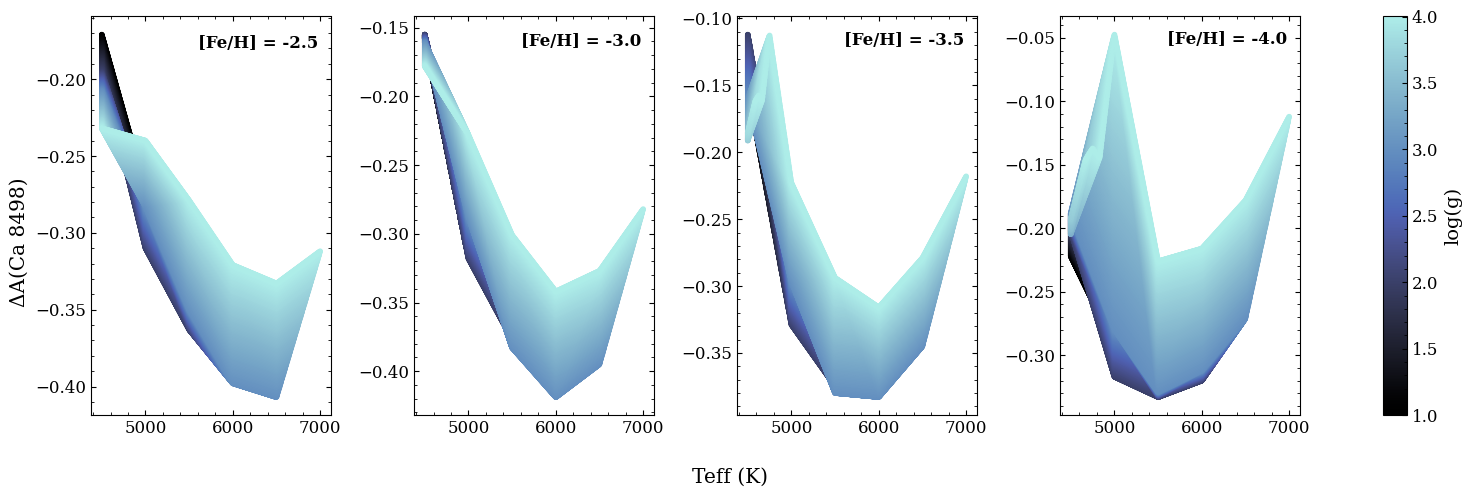

In [4]:
# Applying a ND interpolation to the data
points = caII_corrs[['Teff', 'log_g', 'Fe_H']].values

# Performing the linear interpolation
interp_8498 = LinearNDInterpolator(points, caII_corrs['CaII_8498'].values)

# Getting the interpolated values
teff = np.linspace(min(caII_corrs['Teff']), max(caII_corrs['Teff']), 500)
logg = np.linspace(min(caII_corrs['log_g']), max(caII_corrs['log_g']), 500)
feh = np.linspace(max(caII_corrs['Fe_H']), min(caII_corrs['Fe_H']), 500)

def interp_plot(interp_line, teff_range, logg_range, feh_value):
    """Performts the interpolation for a given range of Teff and logg values at a fixed
    [Fe/H] value.

    Parameters
    ----------
    teff_range : np.array
        Range of Teff values to interpolate.
    logg_range : np.array
        Range of logg values to interpolate.
    feh_value : float
        Fixed [Fe/H] value for the interpolation.

    Returns
    -------
    all_teff : list
        List of Teff values for the interpolated data.
    all_corr : list
        List of interpolated Ca II corrections.
    all_logg : list
        List of logg values for the interpolated data.
    """
    all_teff = []
    all_corr = []
    all_logg = []
    # Looping over the logg values
    for logg in logg_range:
        
        # Determining the correlated correction for the given Teff, logg and [Fe/H]
        corr_8498 = interp_line(teff_range, logg, feh_value)
        
        # Extending to lists
        all_teff.extend(teff)
        all_corr.extend(corr_8498)
        all_logg.extend([logg]*len(teff))
        
    return all_teff, all_corr, all_logg


# Plotting the interpolated data
fig = plt.figure(figsize=(15, 5))
gs = mpl.gridspec.GridSpec(1, 5, wspace=0.05, width_ratios=[0.5, 0.5, 0.5, 0.5, 0.05])

ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[0, 1])  # Row 0, Column 1
ax3 = fig.add_subplot(gs[0, 2])  # Row 0, Column 2
ax4 = fig.add_subplot(gs[0, 3])  # Row 0, Column 3
cax = fig.add_subplot(gs[0, 4]) # Row 0, Column 4

# Defining the color map through which the logg values will be represented
# cmap = plt.get_cmap('viridis')
cmap = cmr.sapphire
norm = Normalize(vmin=logg.min(), vmax=logg.max())

# Plotting the interpolated data for different [Fe/H] values
teff_25, corr_25, logg_25 = interp_plot(interp_8498, teff, logg, -2.5)
ax1.scatter(teff_25, corr_25, c=logg_25, cmap=cmap, norm=norm, marker='.')
ax1.text(5600, -0.18, s='[Fe/H] = -2.5', fontsize=12, fontweight='bold')

teff_30, corr_30, logg_30 = interp_plot(interp_8498, teff, logg, -3.0)
ax2.scatter(teff_30, corr_30, c=logg_30, cmap=cmap, norm=norm, marker='.')
ax2.text(5600, -0.163, s='[Fe/H] = -3.0', fontsize=12, fontweight='bold')

teff_35, corr_35, logg_35 = interp_plot(interp_8498, teff, logg, -3.5)
ax3.scatter(teff_35, corr_35, c=logg_35, cmap=cmap, norm=norm, marker='.')
ax3.text(5600, -0.12, s='[Fe/H] = -3.5', fontsize=12, fontweight='bold')

teff_40, corr_40, logg_40 = interp_plot(interp_8498, teff, logg, -4.0)
cbar = ax4.scatter(teff_40, corr_40, c=logg_40, cmap=cmap, norm=norm, marker='.')
ax4.text(5600, -0.055, s='[Fe/H] = -4.0', fontsize=12, fontweight='bold')

fig.colorbar(cbar, cax=cax, label='log(g)', orientation='vertical')

fig.supylabel('ΔA(Ca 8498)')
fig.supxlabel('Teff (K)')

gs.tight_layout(fig)

plt.savefig('/data/misfit/benlowe/xshooter/results/caII_corr_interpolate/caII_corr_interpolated.pdf', dpi=300, transparent=False, facecolor="white")

In [6]:
interp_8498(5000, 2.0, -3.0)

array(-0.318)

Interpolating using radial basis functions

/home/benlowe/.local/lib/python3.9/site-packages/scipy/interpolate/_rbf.py:268: LinAlgWarning: Ill-conditioned matrix (rcond=1.10681e-17): result may not be accurate.
  self.nodes = linalg.solve(self.A, self.di)


ValueError: Array lengths must be equal

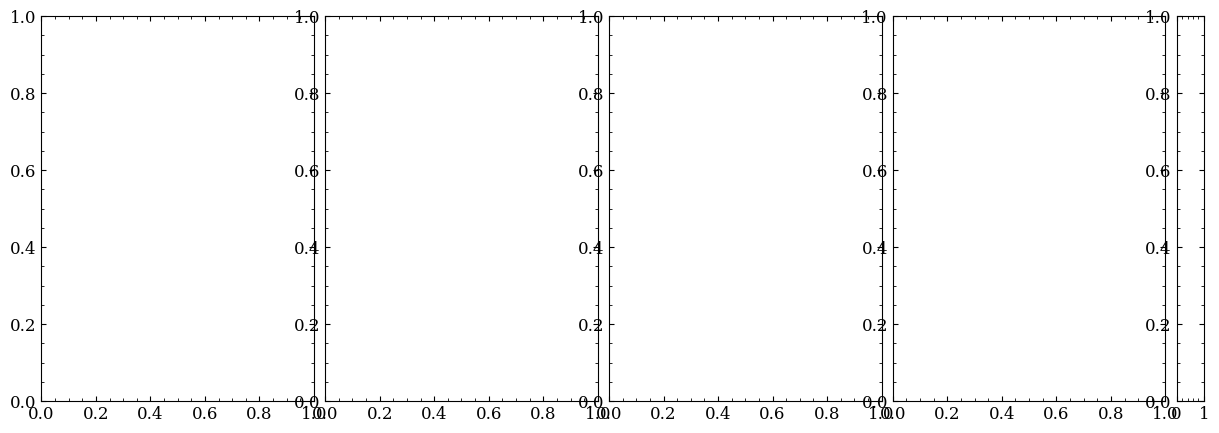

In [35]:
# Applying a ND interpolation to the data
points = caII_corrs[['Teff', 'log_g', 'Fe_H']].values

# Performing the linear interpolation
interp_8498 = Rbf(points[:,0], points[:,1], points[:,2], caII_corrs['CaII_8498'].values, function='multiquadric')

# Getting the interpolated values
teff = np.linspace(min(caII_corrs['Teff']), max(caII_corrs['Teff']), 100)
logg = np.linspace(min(caII_corrs['log_g']), max(caII_corrs['log_g']), 100)
feh = np.linspace(max(caII_corrs['Fe_H']), min(caII_corrs['Fe_H']), 100)

def interp_plot(interp_line, teff_range, logg_range, feh_value):
    """Performts the interpolation for a given range of Teff and logg values at a fixed
    [Fe/H] value.

    Parameters
    ----------
    teff_range : np.array
        Range of Teff values to interpolate.
    logg_range : np.array
        Range of logg values to interpolate.
    feh_value : float
        Fixed [Fe/H] value for the interpolation.

    Returns
    -------
    all_teff : list
        List of Teff values for the interpolated data.
    all_corr : list
        List of interpolated Ca II corrections.
    all_logg : list
        List of logg values for the interpolated data.
    """
    all_teff = []
    all_corr = []
    all_logg = []
    # Looping over the logg values
    for logg in logg_range:
        
        # Determining the correlated correction for the given Teff, logg and [Fe/H]
        corr_8498 = interp_line(teff_range, logg, feh_value)
        
        # Extending to lists
        all_teff.extend(teff)
        all_corr.extend(corr_8498)
        all_logg.extend([logg]*len(teff))
        
    return all_teff, all_corr, all_logg


# Plotting the interpolated data
fig = plt.figure(figsize=(15, 5))
gs = mpl.gridspec.GridSpec(1, 5, wspace=0.05, width_ratios=[0.5, 0.5, 0.5, 0.5, 0.05])

ax1 = fig.add_subplot(gs[0, 0])  # Row 0, Column 0
ax2 = fig.add_subplot(gs[0, 1])  # Row 0, Column 1
ax3 = fig.add_subplot(gs[0, 2])  # Row 0, Column 2
ax4 = fig.add_subplot(gs[0, 3])  # Row 0, Column 3
cax = fig.add_subplot(gs[0, 4]) # Row 0, Column 4

# Defining the color map through which the logg values will be represented
cmap = plt.get_cmap('viridis')
norm = Normalize(vmin=logg.min(), vmax=logg.max())

# Plotting the interpolated data for different [Fe/H] values
teff_25, corr_25, logg_25 = interp_plot(interp_8498, teff, logg, -2.5)
ax1.scatter(teff_25, corr_25, c=logg_25, cmap=cmap, norm=norm, marker='.')
ax1.text(5600, -0.18, s='[Fe/H] = -2.5', fontsize=12, fontweight='bold')

teff_30, corr_30, logg_30 = interp_plot(interp_8498, teff, logg, -3.0)
ax2.scatter(teff_30, corr_30, c=logg_30, cmap=cmap, norm=norm, marker='.')
ax2.text(5600, -0.163, s='[Fe/H] = -3.0', fontsize=12, fontweight='bold')

teff_35, corr_35, logg_35 = interp_plot(interp_8498, teff, logg, -3.5)
ax3.scatter(teff_35, corr_35, c=logg_35, cmap=cmap, norm=norm, marker='.')
ax3.text(5600, -0.12, s='[Fe/H] = -3.5', fontsize=12, fontweight='bold')

teff_40, corr_40, logg_40 = interp_plot(interp_8498, teff, logg, -4.0)
cbar = ax4.scatter(teff_40, corr_40, c=logg_40, cmap=cmap, norm=norm, marker='.')
ax4.text(5600, -0.055, s='[Fe/H] = -4.0', fontsize=12, fontweight='bold')

fig.colorbar(cbar, cax=cax, label='log(g)', orientation='vertical')

fig.supylabel('ΔA(Ca 8498)')
fig.supxlabel('Teff (K)')

gs.tight_layout(fig)

# plt.savefig('/data/misfit/benlowe/results/caII_corr_interpolate/caII_corr_interpolated.png', dpi=300, transparent=False, facecolor="white")

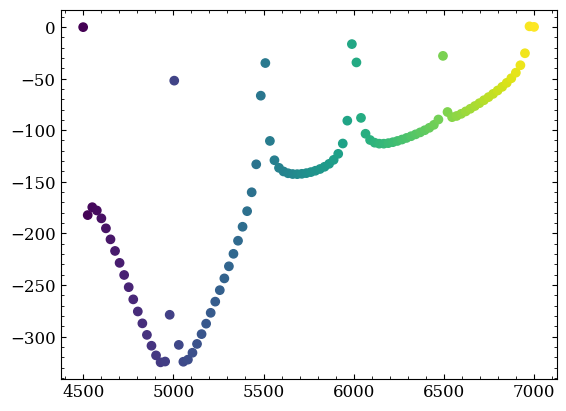

In [42]:
interp_8498(teff, logg, feh)

plt.scatter(teff, interp_8498(teff, logg, feh), c=logg, cmap=cmap, norm=norm)

In [85]:
feh

array([-2.5       , -2.53535354, -2.57070707, -2.60606061, -2.64141414,
       -2.67676768, -2.71212121, -2.74747475, -2.78282828, -2.81818182,
       -2.85353535, -2.88888889, -2.92424242, -2.95959596, -2.99494949,
       -3.03030303, -3.06565657, -3.1010101 , -3.13636364, -3.17171717,
       -3.20707071, -3.24242424, -3.27777778, -3.31313131, -3.34848485,
       -3.38383838, -3.41919192, -3.45454545, -3.48989899, -3.52525253,
       -3.56060606, -3.5959596 , -3.63131313, -3.66666667, -3.7020202 ,
       -3.73737374, -3.77272727, -3.80808081, -3.84343434, -3.87878788,
       -3.91414141, -3.94949495, -3.98484848, -4.02020202, -4.05555556,
       -4.09090909, -4.12626263, -4.16161616, -4.1969697 , -4.23232323,
       -4.26767677, -4.3030303 , -4.33838384, -4.37373737, -4.40909091,
       -4.44444444, -4.47979798, -4.51515152, -4.55050505, -4.58585859,
       -4.62121212, -4.65656566, -4.69191919, -4.72727273, -4.76262626,
       -4.7979798 , -4.83333333, -4.86868687, -4.9040404 , -4.93

In [44]:
logg

array([1.        , 1.03030303, 1.06060606, 1.09090909, 1.12121212,
       1.15151515, 1.18181818, 1.21212121, 1.24242424, 1.27272727,
       1.3030303 , 1.33333333, 1.36363636, 1.39393939, 1.42424242,
       1.45454545, 1.48484848, 1.51515152, 1.54545455, 1.57575758,
       1.60606061, 1.63636364, 1.66666667, 1.6969697 , 1.72727273,
       1.75757576, 1.78787879, 1.81818182, 1.84848485, 1.87878788,
       1.90909091, 1.93939394, 1.96969697, 2.        , 2.03030303,
       2.06060606, 2.09090909, 2.12121212, 2.15151515, 2.18181818,
       2.21212121, 2.24242424, 2.27272727, 2.3030303 , 2.33333333,
       2.36363636, 2.39393939, 2.42424242, 2.45454545, 2.48484848,
       2.51515152, 2.54545455, 2.57575758, 2.60606061, 2.63636364,
       2.66666667, 2.6969697 , 2.72727273, 2.75757576, 2.78787879,
       2.81818182, 2.84848485, 2.87878788, 2.90909091, 2.93939394,
       2.96969697, 3.        , 3.03030303, 3.06060606, 3.09090909,
       3.12121212, 3.15151515, 3.18181818, 3.21212121, 3.24242

3D NLTE Corrections from Lagae et al. (2025) 

In [19]:
ca_corr = h5py.File('/data/misfit/benlowe/xshooter/nlte_corrections/corrections.h5')
print(ca_corr['Acorr'].keys())



def print_h5_structure(g, prefix=''):
    for key in g.keys():
        item = g[key]
        path = f"{prefix}/{key}"
        if isinstance(item, h5py.Group):
            print(f"Group: {path}")
            print_h5_structure(item, path)
        else:
            print(f"Dataset: {path} | Data: {item[:]}")

with h5py.File('/data/misfit/benlowe/xshooter/nlte_corrections/corrections.h5', 'r') as f:
    print_h5_structure(f)


<KeysViewHDF5 ['axis0', 'axis1', 'block0_items', 'block0_values']>
Group: /Acorr
Dataset: /Acorr/axis0 | Data: [b't45g15m20_z370' b't45g15m20_z395' b't45g15m20_z420' b't45g15m20_z445'
 b't45g15m20_z470' b't45g15m20_z495' b't45g15m20_z520' b't45g15m20_z545'
 b't45g15m20_z570' b't45g15m30_z270' b't45g15m30_z295' b't45g15m30_z320'
 b't45g15m30_z345' b't45g15m30_z370' b't45g15m30_z395' b't45g15m30_z420'
 b't45g15m30_z445' b't45g15m30_z470' b't45g15m40_z170' b't45g15m40_z195'
 b't45g15m40_z220' b't45g15m40_z245' b't45g15m40_z270' b't45g15m40_z295'
 b't45g15m40_z320' b't45g15m40_z345' b't45g15m40_z370' b't45g20m20_z370'
 b't45g20m20_z395' b't45g20m20_z420' b't45g20m20_z445' b't45g20m20_z470'
 b't45g20m20_z495' b't45g20m20_z520' b't45g20m20_z545' b't45g20m20_z570'
 b't45g20m30_z270' b't45g20m30_z295' b't45g20m30_z320' b't45g20m30_z345'
 b't45g20m30_z370' b't45g20m30_z395' b't45g20m30_z420' b't45g20m30_z445'
 b't45g20m30_z470' b't45g20m40_z170' b't45g20m40_z195' b't45g20m40_z220'
 b't45g20m40_

In [32]:
# print(ca_corr['/Acorr/axis0'][:])
# print(ca_corr['/Acorr/axis1'][:])
# print(ca_corr['/Acorr/block0_items'][:])
print(ca_corr['/Acorr/block0_values'][:][0])

[128   5 149 ... 148  98  46]
